# Khám phá Dữ liệu (Exploratory Data Analysis)

Notebook này được sử dụng để tải, phân tích và thực hiện các bước làm sạch cơ bản trên tập dữ liệu doanh số thương mại điện tử.

**Mục tiêu:**
- Hiểu rõ cấu trúc dữ liệu
- Phân tích xu hướng và phân phối của các biến
- Tìm kiếm Outliers và Missing Values

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập style mặc định cho biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# Load dữ liệu từ thư mục raw
df = pd.read_csv('../data/raw/ecommerce_dataset_updated.csv')

# Hiển thị 5 dòng đầu tiên
df.head()

,User_ID,Product_ID,Category,Price (Rs.),Discount (%),Final_Price(Rs.),Payment_Method,Purchase_Date
0,337c166f,f414122f-e,Sports,36.53,15,31.05,Net Banking,12-11-2024
1,d38a19bf,fde50f9c-5,Clothing,232.79,20,186.23,Net Banking,09-02-2024
2,d7f5f0b0,0d96fc90-3,Sports,317.02,25,237.76,Credit Card,01-09-2024
3,395d4994,964fc44b-d,Toys,173.19,25,129.89,UPI,01-04-2024
4,a83c145c,d70e2fc6-e,Beauty,244.80,20,195.84,Net Banking,27-09-2024


In [3]:
# Kiểm tra thông tin các trường dữ liệu và Missing Values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3660 entries, 0 to 3659
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           3660 non-null   object 
 1   Product_ID        3660 non-null   object 
 2   Category          3660 non-null   object 
 3   Price (Rs.)       3660 non-null   float64
 4   Discount (%)      3660 non-null   int64  
 5   Final_Price(Rs.)  3660 non-null   float64
 6   Payment_Method    3660 non-null   object 
 7   Purchase_Date     3660 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 228.9+ KB


In [4]:
# Đếm số lượng Missing Values ở từng cột
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0])

Missing values per column:
Series([], dtype: int64)


In [5]:
# Thống kê mô tả các biến số học
df.describe()

,Price (Rs.),Discount (%),Final_Price(Rs.)
count,3660.000000,3660.000000,3660.000000
mean,254.800675,18.825137,206.906579
std,141.682621,14.731338,122.687844
min,10.090000,0.000000,5.890000
25%,134.012500,5.000000,104.512500
50%,253.845000,15.000000,199.185000
75%,377.595000,25.000000,304.117500
max,499.960000,50.000000,496.820000


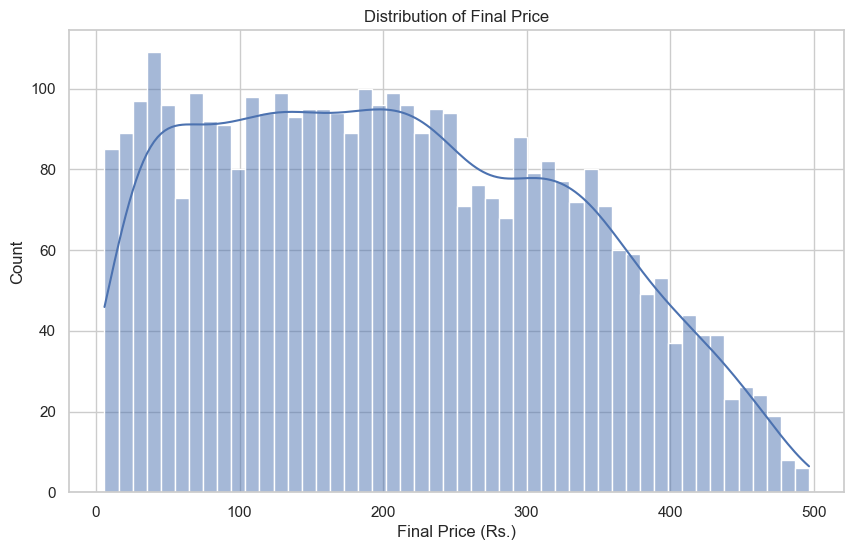

In [6]:
# Trực quan hóa phân phối của mức giá cuối cùng (Final_Price)
sns.histplot(df['Final_Price(Rs.)'], bins=50, kde=True)
plt.title('Distribution of Final Price')
plt.xlabel('Final Price (Rs.)')
plt.ylabel('Count')
plt.show()

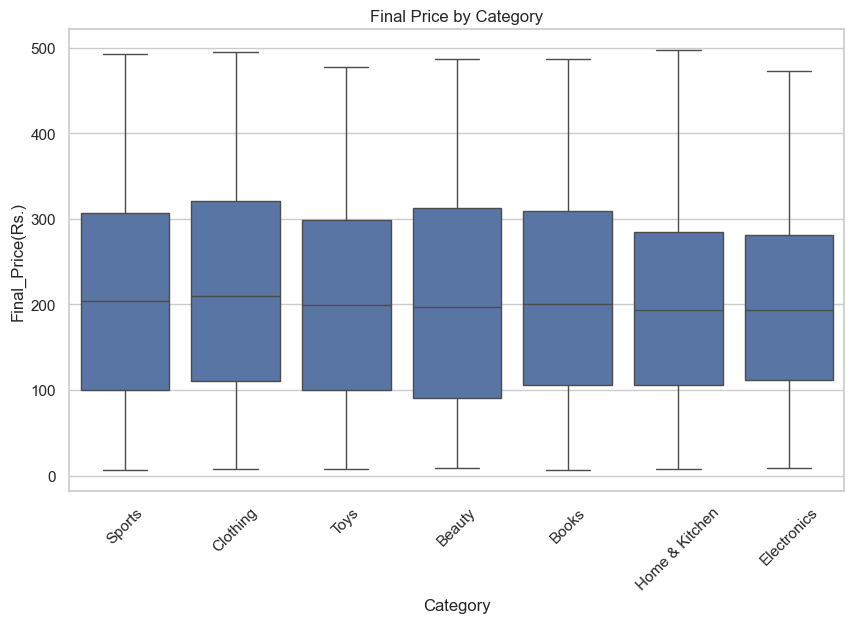

In [7]:
# Trực quan hóa giá theo từng danh mục (Category)
sns.boxplot(x='Category', y='Final_Price(Rs.)', data=df)
plt.title('Final Price by Category')
plt.xticks(rotation=45)
plt.show()

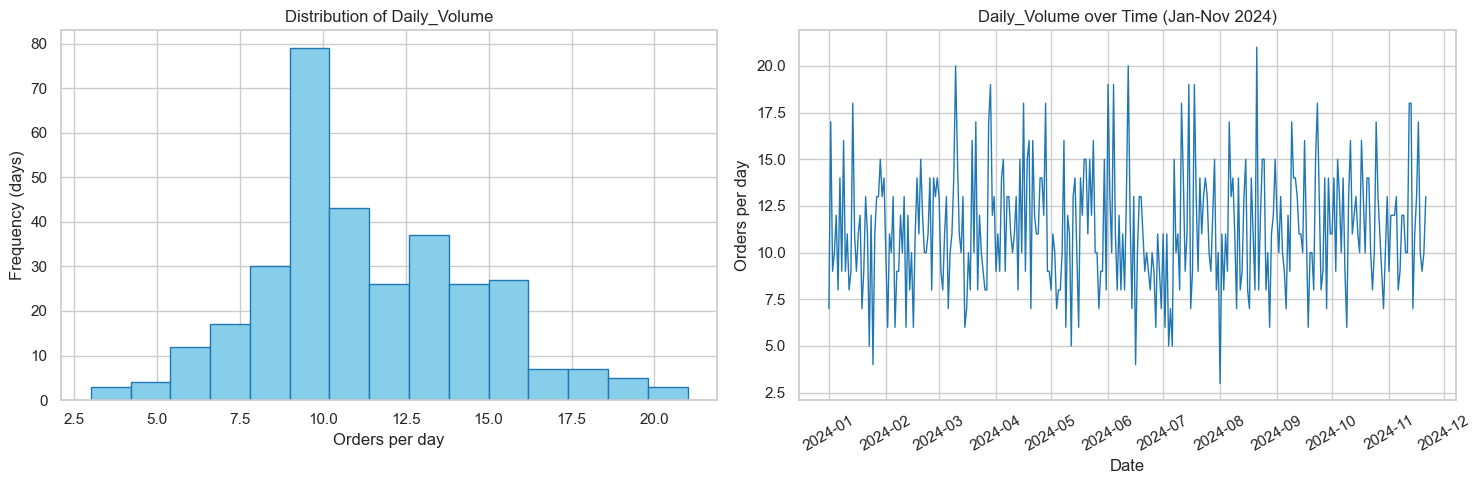

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Nhóm dữ liệu theo ngày để tạo cột Daily_Volume
df['Purchase_Date'] = pd.to_datetime(df['Purchase_Date'], format='%d-%m-%Y')
df_daily = df.groupby('Purchase_Date').size().reset_index(name='Daily_Volume')
df_daily = df_daily.sort_values('Purchase_Date')

# 2. Cài đặt khung vẽ 1 hàng 2 cột
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.set_theme(style="whitegrid")

# Biểu đồ trái: Distribution of Daily_Volume
axes[0].hist(df_daily['Daily_Volume'], bins=15, color='skyblue', edgecolor='tab:blue')
axes[0].set_title('Distribution of Daily_Volume')
axes[0].set_xlabel('Orders per day')
axes[0].set_ylabel('Frequency (days)')

# Biểu đồ phải: Daily_Volume over Time
axes[1].plot(df_daily['Purchase_Date'], df_daily['Daily_Volume'], color='tab:blue', linewidth=1)
axes[1].set_title('Daily_Volume over Time (Jan-Nov 2024)')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Orders per day')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

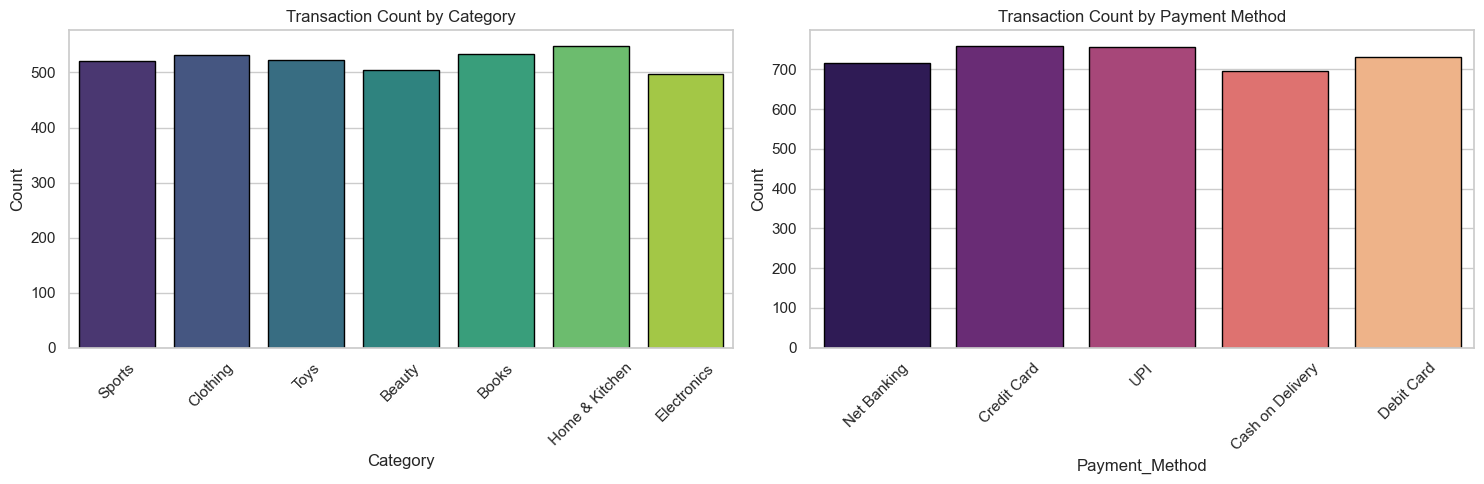

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Cài đặt khung vẽ 1 hàng 2 cột
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.set_theme(style="whitegrid")

# Biểu đồ trái: Transaction Count by Category
sns.countplot(data=df, x='Category', hue='Category', palette='viridis', ax=axes[0], edgecolor='black', legend=False)
axes[0].set_title('Transaction Count by Category')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

# Biểu đồ phải: Transaction Count by Payment Method
sns.countplot(data=df, x='Payment_Method', hue='Payment_Method', palette='magma', ax=axes[1], edgecolor='black', legend=False)
axes[1].set_title('Transaction Count by Payment Method')
axes[1].set_xlabel('Payment_Method')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()